In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

In [ ]:
rows = []

for run_dir in Path("results").iterdir():
    csv_path = run_dir / "seed-0" / "cv_results.csv"

    if not csv_path.exists():
        continue

    df = pd.read_csv(csv_path)

    rows.append({
        "Experiment": run_dir.name,
        "CV accuracy (%)": 100 * df["val_accuracy"].mean(),
        "Std (%)": 100 * df["val_accuracy"].std(),
        "CV loss": df["val_loss"].mean(),
        "Best epoch": df["best_epoch"].mean()
    })

results = pd.DataFrame(rows)
results = results.sort_values("CV accuracy (%)", ascending=False)

display(results.round(3))

,Experiment,CV accuracy (%),Std (%),CV loss,Best epoch
5,lstm_h512_wd03,93.145,0.277,0.197,12.8
2,lstm_h512_wd01,93.100,0.316,0.194,9.8
1,lstm_h256_wd01,93.063,0.199,0.194,10.8
0,lstm_h128_wd01,92.999,0.196,0.192,12.0
4,lstm_h512_wd02,92.992,0.444,0.194,10.2
3,lstm_h512_wd01_finetuned,92.024,0.198,0.221,2.4
6,pilot_lstm_h128,87.145,0.772,0.299,2.0
7,pool_fasttext300,86.992,0.100,0.302,49.8
8,pool_glove50,79.015,0.314,0.438,48.2


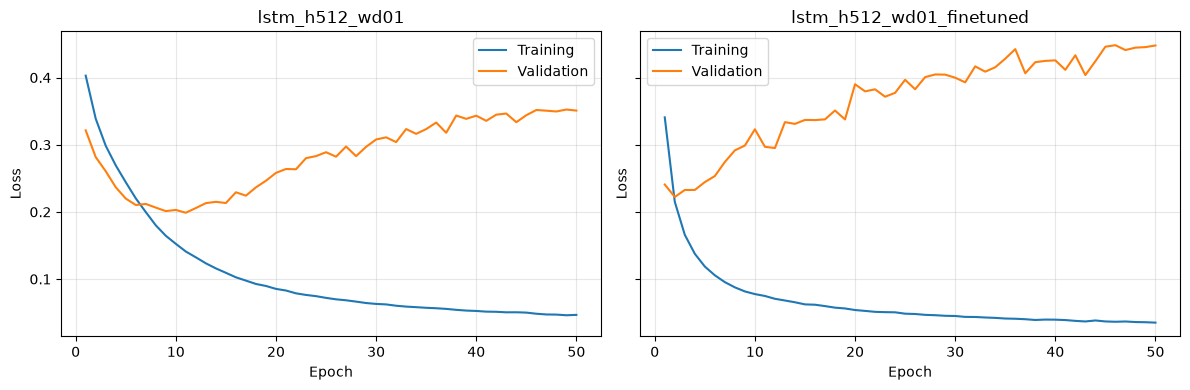

In [ ]:
experiments = [
    "lstm_h512_wd01",
    "lstm_h512_wd01_finetuned"
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, name in zip(axes, experiments):
    path = Path("results") / name / "seed-0" / "epoch_metrics.csv"
    df = pd.read_csv(path)

    # Average across the 5 CV folds
    curves = df.groupby("epoch")[["train_loss", "val_loss"]].mean()

    ax.plot(curves.index, curves["train_loss"], label="Training")
    ax.plot(curves.index, curves["val_loss"], label="Validation")

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RUNS = {
    "GloVe 50D + Pool": "pool_glove50",
    "FastText 300D + Pool": "pool_fasttext300",
    "LSTM H=128": "lstm_h128_wd01",
    "LSTM H=256": "lstm_h256_wd01",
    "LSTM H=512": "lstm_h512_wd01",
    "LSTM Dropout=0.2": "lstm_h512_wd02",
    "LSTM Dropout=0.3": "lstm_h512_wd03",
    "LSTM Fine-tuned": "lstm_h512_wd01_finetuned",
}

BASE_URL = "https://raw.githubusercontent.com/alexandrosslav/NLP-Assignment-2/main/results"
local_dir = next(
    (p for p in [Path("results"), Path("../results")] if p.is_dir()),
    None
)

def load_results(filename):
    frames = []

    for name, run_id in RUNS.items():
        if local_dir is not None:
            path = local_dir / run_id / "seed-0" / filename
        else:
            path = f"{BASE_URL}/{run_id}/seed-0/{filename}"

        df = pd.read_csv(path)
        df["model"] = name
        frames.append(df)

    return pd.concat(frames, ignore_index=True)

cv = load_results("cv_results.csv")
history = load_results("epoch_metrics.csv")

print(f"Loaded {cv['model'].nunique()} experiments, "
      f"{len(cv)} CV folds, and {len(history)} epoch records.")

Loaded 8 experiments, 40 CV folds, and 2000 epoch records.


,accuracy,sd,val_loss,best_epoch
model,,,,
LSTM Dropout=0.3,93.145,0.277,0.197,12.8
LSTM H=512,93.100,0.316,0.194,9.8
LSTM H=256,93.063,0.199,0.194,10.8
LSTM H=128,92.999,0.196,0.192,12.0
LSTM Dropout=0.2,92.992,0.444,0.194,10.2
LSTM Fine-tuned,92.024,0.198,0.221,2.4
FastText 300D + Pool,86.992,0.100,0.302,49.8
GloVe 50D + Pool,79.015,0.314,0.438,48.2


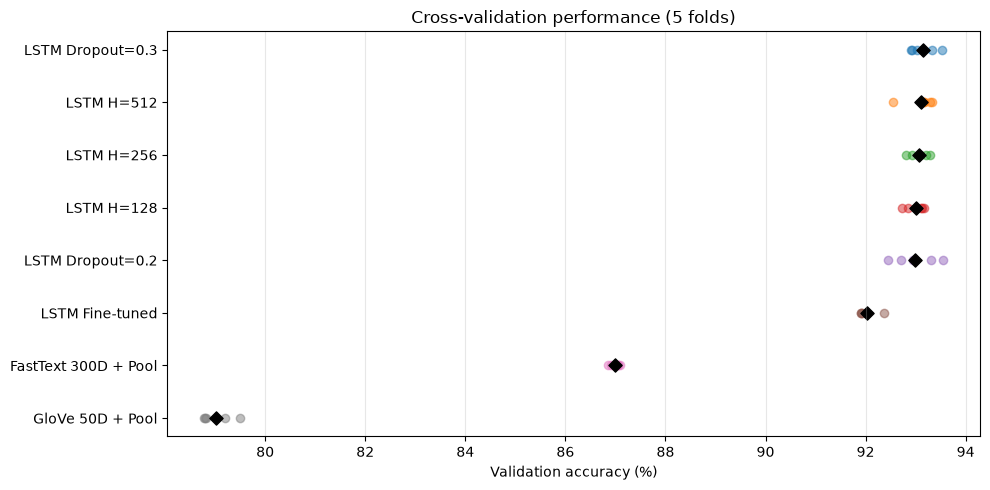

In [4]:
summary = cv.groupby("model", sort=False).agg(
    accuracy=("val_accuracy", lambda x: 100 * x.mean()),
    sd=("val_accuracy", lambda x: 100 * x.std()),
    val_loss=("val_loss", "mean"),
    best_epoch=("best_epoch", "mean")
)

summary = summary.sort_values("accuracy", ascending=False)

display(summary.round(3))

# Accuracy across the 5 folds
fig, ax = plt.subplots(figsize=(10, 5))

for i, model in enumerate(summary.index):
    values = cv.loc[cv.model == model, "val_accuracy"] * 100

    ax.scatter(values, [i] * len(values), alpha=0.5)
    ax.scatter(values.mean(), i, marker="D", color="black", s=45)

ax.set_yticks(range(len(summary)), summary.index)
ax.invert_yaxis()
ax.set_xlabel("Validation accuracy (%)")
ax.set_title("Cross-validation performance (5 folds)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

,Mean difference (pp),SD (pp),Positive folds
Comparison,,,
FastText vs GloVe,7.976,0.354,5/5
LSTM vs Pool,6.008,0.276,5/5
H=256 vs H=128,0.064,0.059,4/5
H=512 vs H=256,0.037,0.438,3/5
Dropout 0.2 vs 0.1,-0.108,0.538,2/5
Dropout 0.3 vs 0.1,0.045,0.350,3/5
Fine-tuned vs Frozen,-1.076,0.333,0/5


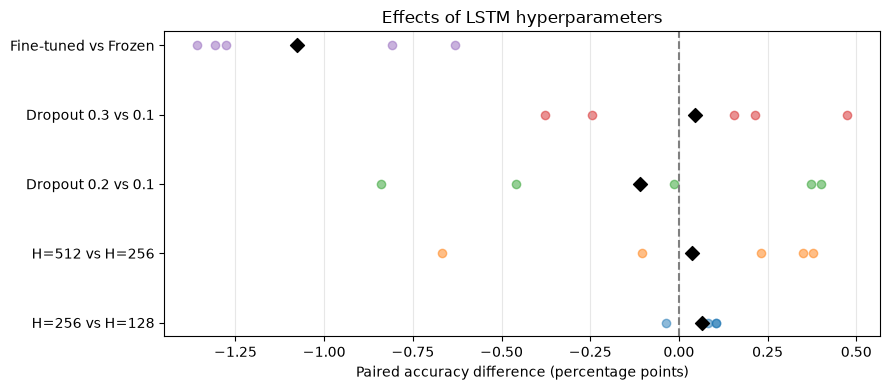

In [5]:
comparisons = [
    ("FastText vs GloVe", "FastText 300D + Pool", "GloVe 50D + Pool"),
    ("LSTM vs Pool", "LSTM H=128", "FastText 300D + Pool"),
    ("H=256 vs H=128", "LSTM H=256", "LSTM H=128"),
    ("H=512 vs H=256", "LSTM H=512", "LSTM H=256"),
    ("Dropout 0.2 vs 0.1", "LSTM Dropout=0.2", "LSTM H=512"),
    ("Dropout 0.3 vs 0.1", "LSTM Dropout=0.3", "LSTM H=512"),
    ("Fine-tuned vs Frozen", "LSTM Fine-tuned", "LSTM H=512"),
]

differences = {}
rows = []

for label, model_a, model_b in comparisons:
    a = cv[cv.model == model_a].set_index("fold")["val_accuracy"]
    b = cv[cv.model == model_b].set_index("fold")["val_accuracy"]

    diff = (a - b) * 100  # percentage points
    differences[label] = diff

    rows.append({
        "Comparison": label,
        "Mean difference (pp)": diff.mean(),
        "SD (pp)": diff.std(),
        "Positive folds": f"{(diff > 0).sum()}/5"
    })

comparison_df = pd.DataFrame(rows).set_index("Comparison")
display(comparison_df.round(3))

# Plot the smaller LSTM hyperparameter effects separately
fig, ax = plt.subplots(figsize=(9, 4))

for i, (label, diff) in enumerate(list(differences.items())[2:]):
    ax.scatter(diff.values, [i] * len(diff), alpha=0.5)
    ax.scatter(diff.mean(), i, color="black", marker="D", s=50)

ax.set_yticks(range(5), list(differences.keys())[2:])
ax.axvline(0, color="gray", linestyle="--")
ax.set_xlabel("Paired accuracy difference (percentage points)")
ax.set_title("Effects of LSTM hyperparameters")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

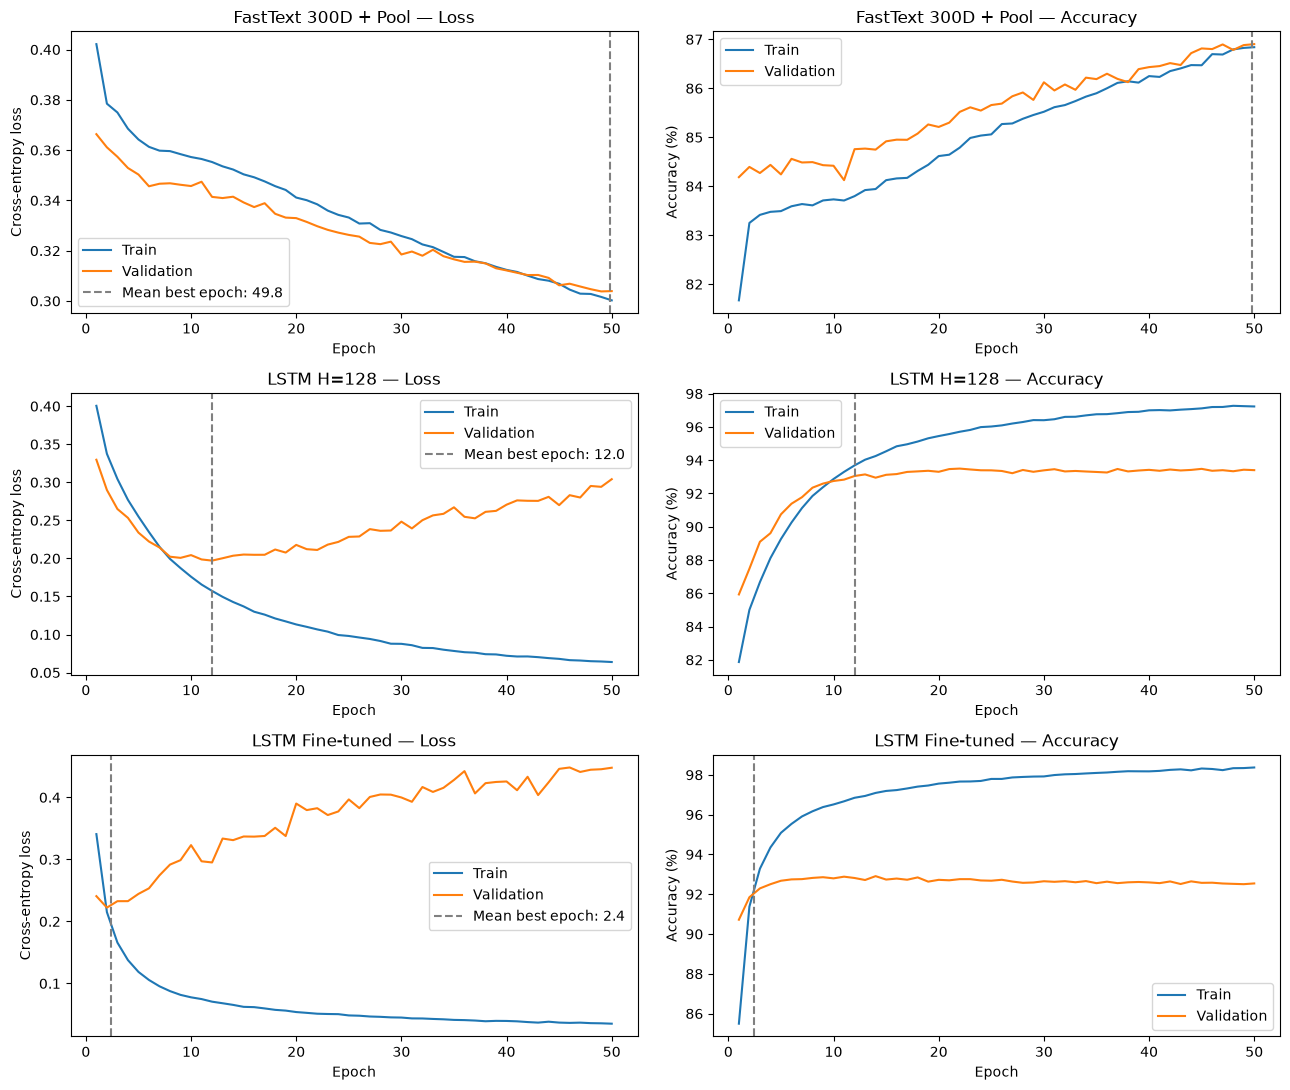

In [6]:
models = [
    "FastText 300D + Pool",
    "LSTM H=128",
    "LSTM Fine-tuned"
]

fig, axes = plt.subplots(3, 2, figsize=(13, 11))

for i, model in enumerate(models):
    df = history[history.model == model]

    curves = df.groupby("epoch").agg(
        train_loss=("train_loss", "mean"),
        val_loss=("val_loss", "mean"),
        train_accuracy=("train_accuracy", "mean"),
        val_accuracy=("val_accuracy", "mean")
    )

    best_epoch = cv[cv.model == model]["best_epoch"].mean()

    # Loss
    ax = axes[i, 0]
    ax.plot(curves.index, curves.train_loss, label="Train")
    ax.plot(curves.index, curves.val_loss, label="Validation")
    ax.axvline(best_epoch, color="gray", linestyle="--",
               label=f"Mean best epoch: {best_epoch:.1f}")
    ax.set_title(f"{model} — Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-entropy loss")
    ax.legend()

    # Accuracy
    ax = axes[i, 1]
    ax.plot(curves.index, curves.train_accuracy * 100, label="Train")
    ax.plot(curves.index, curves.val_accuracy * 100, label="Validation")
    ax.axvline(best_epoch, color="gray", linestyle="--")
    ax.set_title(f"{model} — Accuracy")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy (%)")
    ax.legend()

plt.tight_layout()
plt.show()

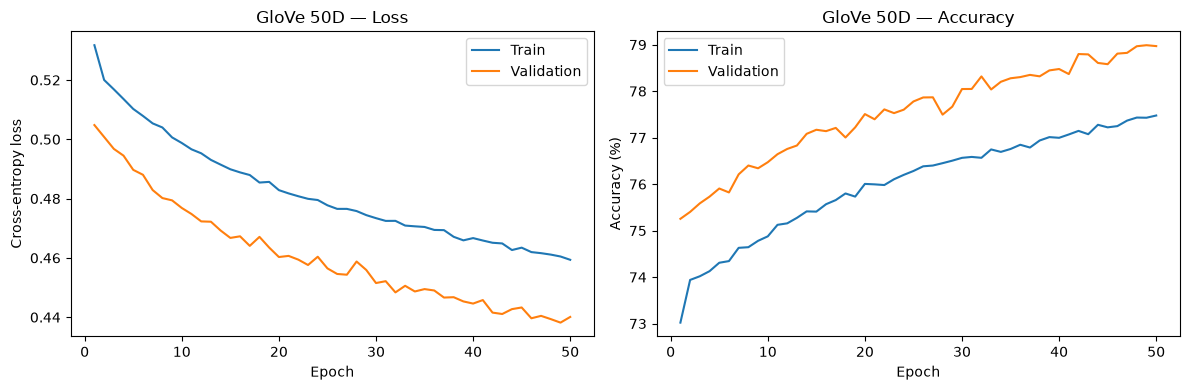

In [7]:
df = history[history.model == "GloVe 50D + Pool"]

curves = df.groupby("epoch").mean(numeric_only=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(curves.index, curves.train_loss, label="Train")
axes[0].plot(curves.index, curves.val_loss, label="Validation")
axes[0].set_title("GloVe 50D — Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

# Accuracy
axes[1].plot(curves.index, curves.train_accuracy * 100, label="Train")
axes[1].plot(curves.index, curves.val_accuracy * 100, label="Validation")
axes[1].set_title("GloVe 50D — Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()

plt.tight_layout()
plt.show()